In [1]:
import matplotlib.pyplot as plt

from sklearn.model_selection import cross_validate
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.preprocessing import Normalizer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight
import pandas as pd
import numpy as np
#from aerosound.params import *
from keras import Sequential, layers
from keras.metrics import Recall
from keras.callbacks import EarlyStopping
from keras.optimizers import Adam


In [2]:

def data_obtain_rnn(path):
# obtain data from the path and saperated the data by machine type and save the dataframes into a dictionary and return to this dictionary
    data_ori = pd.read_csv(path)
    machine_dfs = {}

    for machine in data_ori['machine'].unique():
        machine_dfs[machine] = data_ori[
            data_ori['machine'] == machine
        ].copy()

    print(machine_dfs.keys())
    return machine_dfs

def prep_data_rnn(data_ori):
    data = data_ori.copy()
    data = data.drop_duplicates()
    data['label'] = data['label'].map({
        'normal': 0,
        'abnormal': 1
    })
    data = data.drop(columns=['noise','machine','id','file','snr','file_num'])
    data = data.rename(columns={'label':'target'})
    X = data.drop(columns = 'target')
    y = data['target']
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=1,
        stratify=y
    )
    X_train_rnn = X_train.to_numpy().reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )

    #try: valuable!!!
    X_train_rnn = X_train_rnn * 100

    # X_test_rnn = X_test.to_numpy().reshape(
    #     X_test.shape[0],
    #     X_test.shape[1],
    #     1
    # )
    return X_train_rnn, X_test, y_train, y_test

def rnn_LSTM(X_train_rnn, y_train):
    ''' estublish the model, compile the model, train the model '''
    #estublish the model
    model = Sequential([
        layers.Input(shape=(X_train_rnn.shape[1],X_train_rnn.shape[2])),
        layers.LSTM(32),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    #compile the model
    model.compile(
        optimizer = Adam(learning_rate=0.00005),
        loss = 'binary_crossentropy',
        metrics=[
            Recall(name='recall'),
            'accuracy',
            'AUC'
        ]
    )

    #define early stop
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    #add class weight for abnormal samples, because of unbalanced normal/abnormal data
    classes = np.unique(y_train)
    weights = compute_class_weight(
        class_weight='balanced',
        classes=classes,
        y=np.asarray(y_train)
    )
    class_weights = dict(zip(classes, weights))

    #train the model
    history = model.fit(
        X_train_rnn,
        y_train,
        epochs=500,
        batch_size=32,
        validation_split=0.2,
        callbacks=[early_stop],
        class_weight=class_weights
    )
    return model, history

def predict_sound(model, X_pred):
    ''' predict normal/abnormal '''
    X_pred_rnn = X_pred.to_numpy().reshape(
        X_pred.shape[0],
        X_pred.shape[1],
        1
    )
    X_pred_rnn = X_pred_rnn * 100
    y = model.predict(X_pred_rnn)
    return (y >= 0.35).astype(int)


def model_evaluate(model, X_test, y_test):
    ''' show the performance of the model '''
    y_pred = predict_sound(model, X_test).ravel()
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0,1],
        display_labels=["Normal", "Abnormal"]
    )

    plt.title("Confusion Matrix")
    plt.show()

In [2]:
machine_dfs = data_obtain_rnn('../../features_0dB.csv')
data_ori = machine_dfs['fan']
X_train_rnn, X_test, y_train, y_test = prep_data_rnn(data_ori)

dict_keys(['fan', 'pump', 'slider', 'valve'])


In [6]:
X_train_rnn = pd.DataFrame(X_train_rnn.reshape(X_train_rnn.shape[0],X_train_rnn.shape[1]))
X_train_rnn

,0,1,2,3,4,5,6,7,8,9,...,90,91,92,93,94,95,96,97,98,99
0,0.007314,0.006482,0.007011,0.006897,0.006982,0.006527,0.006185,0.006808,0.007282,0.006702,...,0.006625,0.006367,0.006422,0.006648,0.007175,0.006296,0.006657,0.006770,0.007024,0.006441
1,0.006594,0.006208,0.006774,0.005829,0.006806,0.005923,0.005419,0.005799,0.005872,0.005891,...,0.006232,0.005742,0.005142,0.006031,0.005316,0.005374,0.005677,0.006009,0.006871,0.005841
2,0.005931,0.006199,0.006143,0.007534,0.007131,0.006353,0.005650,0.005815,0.007164,0.007650,...,0.007615,0.010295,0.008070,0.006506,0.005764,0.006970,0.007389,0.008205,0.006327,0.005210
3,0.005840,0.005608,0.006206,0.006242,0.004998,0.005282,0.005815,0.005597,0.005356,0.006477,...,0.005537,0.006464,0.007279,0.007052,0.004730,0.005536,0.006059,0.005568,0.005700,0.006274
4,0.006970,0.004974,0.005189,0.006008,0.005925,0.005360,0.006928,0.005439,0.007967,0.006970,...,0.004559,0.005293,0.006051,0.004861,0.005512,0.004925,0.005346,0.005538,0.005673,0.005835
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4435,0.006140,0.005807,0.005738,0.006273,0.006356,0.006861,0.006122,0.006313,0.006775,0.006679,...,0.006114,0.006331,0.006675,0.005808,0.006742,0.005609,0.006131,0.007159,0.005421,0.006065
4436,0.006512,0.005765,0.006472,0.006994,0.007566,0.007151,0.006418,0.007050,0.007545,0.006404,...,0.006985,0.007705,0.007249,0.006724,0.006411,0.007235,0.007348,0.006824,0.006688,0.006598
4437,0.005731,0.006692,0.006232,0.006768,0.006524,0.006732,0.007008,0.005684,0.006132,0.006447,...,0.006395,0.006644,0.006072,0.006277,0.006477,0.005535,0.006147,0.006400,0.006141,0.006975
4438,0.006074,0.005969,0.005943,0.005895,0.005646,0.007569,0.007503,0.007197,0.006652,0.006012,...,0.006292,0.005834,0.005712,0.006174,0.006075,0.005392,0.005699,0.006414,0.005407,0.006804


In [10]:
y_train = pd.DataFrame(y_train)
y_train.value_counts()

target
0         3260
1         1180
Name: count, dtype: int64

In [3]:
machine_dfs = data_obtain_rnn('../../features_0dB.csv')
data_ori = machine_dfs['fan']
X_train_rnn, X_test, y_train, y_test = prep_data_rnn(data_ori)

dict_keys(['fan', 'pump', 'slider', 'valve'])


In [6]:
rnn_model, history = rnn_LSTM(X_train_rnn, y_train)


Epoch 1/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - AUC: 0.5168 - accuracy: 0.2644 - loss: 0.6930 - recall: 1.0000 - val_AUC: 0.5223 - val_accuracy: 0.2714 - val_loss: 0.7121 - val_recall: 1.0000
Epoch 2/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.5173 - accuracy: 0.2644 - loss: 0.6923 - recall: 1.0000 - val_AUC: 0.5224 - val_accuracy: 0.2714 - val_loss: 0.7054 - val_recall: 1.0000
Epoch 3/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.4991 - accuracy: 0.2644 - loss: 0.6919 - recall: 1.0000 - val_AUC: 0.5662 - val_accuracy: 0.2714 - val_loss: 0.7038 - val_recall: 1.0000
Epoch 4/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - AUC: 0.5075 - accuracy: 0.2641 - loss: 0.6916 - recall: 0.9989 - val_AUC: 0.5690 - val_accuracy: 0.2714 - val_loss: 0.6996 - val_recall: 1.0000
Epoch 5/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - AUC: 0.5314 - accuracy: 0.2635 - loss: 0.6913 - recall: 0.9968 - val_AUC: 0.5765 - val_accuracy: 0.2714 - val_loss: 0.6993 - val_recall: 1.0000
Epoc

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step


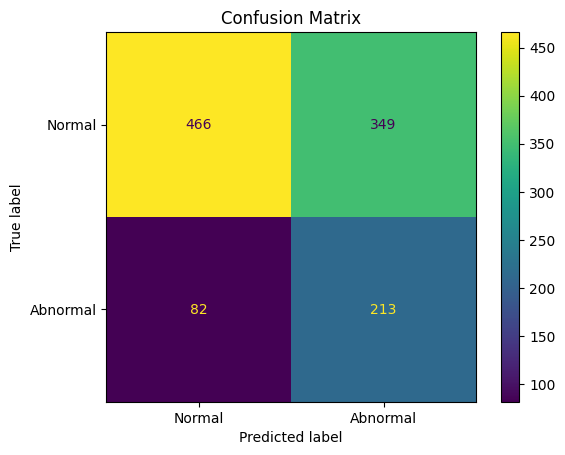

In [7]:
model_evaluate(rnn_model, X_test, y_test)

In [10]:
rnn_model.save("rnn_model_std.keras")

In [ ]:
print("Min:", X_train_rnn.min())
print("Max:", X_train_rnn.max())
print("Mean:", X_train_rnn.mean())
print("Std:", X_train_rnn.std())

Min: 0.19292824
Max: 2.0893737999999997
Mean: 0.6515854700531757
Std: 0.12107950754203381


## Now trying 400 features for rnn model

In [2]:
import os
print(os.getcwd())

/Users/shaotongwang/code/Marie-Jourdain/aerosound/aerosound/model


In [3]:
os.chdir("../..")
print(os.getcwd())

/Users/shaotongwang/code/Marie-Jourdain/aerosound


In [4]:
from aerosound.ml_logic.data import *
from aerosound.ml_logic.preprocessing import *

In [15]:
def get_data_rnn(path):
# obtain data from the path and saperated the data by machine type and save the dataframes into a dictionary and return to this dictionary
    audio_paths = list(Path(path).rglob("*.wav"))
    df = build_dataset(audio_paths)
    machine_dfs = {}

    for machine in df['machine'].unique():
        machine_dfs[machine] = df[
            df['machine'] == machine
        ].copy()

    print(machine_dfs.keys())
    return machine_dfs

In [6]:
# test if the code is updated in notebook
import inspect
import aerosound.ml_logic.preprocessing as prep

print(inspect.getsource(prep.extract_type_features))
#print(inspect.getsource(prep.preprocess_audio))

def extract_type_features(mono_signal):
    """Split a mono audio time series into 100 time windows and convert them to features
    representing the standard deviation of the audio amplitude within each time window.

    Parameters
    ----------
    mono_signal : np.ndarray
        Mono audio time series with shape (n_samples, ).

    Returns
    -------
    extracted_features : np.ndarray
        Features from the splitting of the mono signal into time windows representing
        the standard deviation of the audio amplitude within one time window with
        shape (100,).
    """

    split_means = np.array_split(mono_signal, 400)

    slice_types = [np.mean(np.diff(np.signbit(s)) != 0) for s in split_means]

    extracted_features = np.array(slice_types)
    return extracted_features



In [16]:
machine_dfs = get_data_rnn('raw_data/0db_fan')
machine_dfs

dict_keys(['fan'])


{'fan':      noise machine     id     label          file  snr     f_000     f_001  \
 0     0_dB     fan  id_00  abnormal  00000059.wav    0  0.040100  0.060150   
 1     0_dB     fan  id_00  abnormal  00000071.wav    0  0.042607  0.050125   
 2     0_dB     fan  id_00  abnormal  00000065.wav    0  0.037594  0.032581   
 3     0_dB     fan  id_00  abnormal  00000273.wav    0  0.057644  0.042607   
 4     0_dB     fan  id_00  abnormal  00000267.wav    0  0.045113  0.052632   
 ...    ...     ...    ...       ...           ...  ...       ...       ...   
 5545  0_dB     fan  id_02    normal  00000068.wav    0  0.117794  0.095238   
 5546  0_dB     fan  id_02    normal  00000040.wav    0  0.102757  0.122807   
 5547  0_dB     fan  id_02    normal  00000726.wav    0  0.125313  0.125313   
 5548  0_dB     fan  id_02    normal  00000732.wav    0  0.085213  0.130326   
 5549  0_dB     fan  id_02    normal  00000054.wav    0  0.037594  0.075188   
 
          f_002     f_003  ...     f_390   

In [17]:
data_ori = machine_dfs['fan']
data_ori


,noise,machine,id,label,file,snr,f_000,f_001,f_002,f_003,...,f_390,f_391,f_392,f_393,f_394,f_395,f_396,f_397,f_398,f_399
0,0_dB,fan,id_00,abnormal,00000059.wav,0,0.040100,0.060150,0.052632,0.037594,...,0.020050,0.042607,0.065163,0.047619,0.037594,0.047619,0.060150,0.047619,0.022556,0.047619
1,0_dB,fan,id_00,abnormal,00000071.wav,0,0.042607,0.050125,0.022556,0.032581,...,0.017544,0.052632,0.047619,0.035088,0.022556,0.032581,0.032581,0.040100,0.037594,0.050125
2,0_dB,fan,id_00,abnormal,00000065.wav,0,0.037594,0.032581,0.045113,0.037594,...,0.027569,0.017544,0.030075,0.047619,0.027569,0.045113,0.077694,0.047619,0.045113,0.040100
3,0_dB,fan,id_00,abnormal,00000273.wav,0,0.057644,0.042607,0.045113,0.077694,...,0.072682,0.072682,0.060150,0.072682,0.082707,0.097744,0.082707,0.102757,0.065163,0.090226
4,0_dB,fan,id_00,abnormal,00000267.wav,0,0.045113,0.052632,0.055138,0.052632,...,0.197995,0.220551,0.197995,0.132832,0.110276,0.152882,0.152882,0.205514,0.132832,0.142857
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5545,0_dB,fan,id_02,normal,00000068.wav,0,0.117794,0.095238,0.082707,0.117794,...,0.087719,0.120301,0.087719,0.125313,0.082707,0.110276,0.147870,0.120301,0.107769,0.102757
5546,0_dB,fan,id_02,normal,00000040.wav,0,0.102757,0.122807,0.125313,0.155388,...,0.120301,0.112782,0.107769,0.132832,0.100251,0.117794,0.105263,0.137845,0.115288,0.105263
5547,0_dB,fan,id_02,normal,00000726.wav,0,0.125313,0.125313,0.115288,0.107769,...,0.115288,0.142857,0.117794,0.085213,0.140351,0.127820,0.092732,0.122807,0.110276,0.112782
5548,0_dB,fan,id_02,normal,00000732.wav,0,0.085213,0.130326,0.102757,0.132832,...,0.127820,0.097744,0.117794,0.122807,0.095238,0.090226,0.100251,0.077694,0.107769,0.112782


In [9]:
data_ori.to_csv("aerosound/model/0db_fan_zcr.csv", index=False)

In [10]:
data_ori.noise.value_counts()

noise
0_dB    5550
Name: count, dtype: int64

In [11]:
data_ori.machine.value_counts()

machine
fan    5550
Name: count, dtype: int64

In [18]:
def prep_data_rnn(data_ori):
    data = data_ori.copy()
    data = data.drop_duplicates()
    data['label'] = data['label'].map({
        'normal': 0,
        'abnormal': 1
    })
    data = data.drop(columns=['noise','machine','id','file','snr'])
    data = data.rename(columns={'label':'target'})
    X = data.drop(columns = 'target')
    y = data['target']
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=1,
        stratify=y
    )
    X_train_rnn = X_train.to_numpy().reshape(
        X_train.shape[0],
        X_train.shape[1],
        1
    )

    #try: valuable!!!
    X_train_rnn = X_train_rnn * 10

    # X_test_rnn = X_test.to_numpy().reshape(
    #     X_test.shape[0],
    #     X_test.shape[1],
    #     1
    # )
    return X_train_rnn, X_test, y_train, y_test

In [19]:
X_train_rnn, X_test, y_train, y_test = prep_data_rnn(data_ori)

In [20]:
print("Min:", X_train_rnn.min())
print("Max:", X_train_rnn.max())
print("Mean:", X_train_rnn.mean())
print("Std:", X_train_rnn.std())

Min: 0.02506265664160401
Max: 4.335839598997493
Mean: 0.8966668077852286
Std: 0.34150254456081075


In [21]:
def rnn_LSTM(X_train_rnn, y_train):
    ''' estublish the model, compile the model, train the model '''
    #estublish the model
    model = Sequential([
        layers.Input(shape=(X_train_rnn.shape[1],X_train_rnn.shape[2])),
        layers.LSTM(32),
        layers.Dense(16, activation='relu'),
        layers.Dense(1, activation='sigmoid')
    ])

    #compile the model
    model.compile(
        optimizer = Adam(learning_rate=0.0005, clipnorm=1.0),
        loss = 'binary_crossentropy',
        metrics=[
            Recall(name='recall'),
            'accuracy',
            'AUC'
        ]
    )

    #define early stop
    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=12,
        restore_best_weights=True
    )

    #add class weight for abnormal samples, because of unbalanced normal/abnormal data
    classes = np.unique(y_train)
    weights = compute_class_weight(
        class_weight='balanced',
        classes=classes,
        y=np.asarray(y_train)
    )
    class_weights = dict(zip(classes, weights))

    #train the model
    history = model.fit(
        X_train_rnn,
        y_train,
        epochs=500,
        batch_size=32,
        validation_split=0.2,
        callbacks=[early_stop],
        class_weight=class_weights
    )
    return model, history


In [22]:

def predict_sound(model, X_pred):
    ''' predict normal/abnormal '''
    X_pred_rnn = X_pred.to_numpy().reshape(
        X_pred.shape[0],
        X_pred.shape[1],
        1
    )
    X_pred_rnn = X_pred_rnn * 10
    y = model.predict(X_pred_rnn)
    return (y >= 0.5).astype(int), y


def model_evaluate(model, X_test, y_test):
    ''' show the performance of the model '''
    y_pred = predict_sound(model, X_test).ravel()
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=[0,1],
        display_labels=["Normal", "Abnormal"]
    )

    plt.title("Confusion Matrix")
    plt.show()

In [23]:
rnn_model, history = rnn_LSTM(X_train_rnn, y_train)

Epoch 1/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - AUC: 0.5356 - accuracy: 0.6810 - loss: 0.6911 - recall: 0.2002 - val_AUC: 0.5656 - val_accuracy: 0.7579 - val_loss: 0.6721 - val_recall: 0.1452
Epoch 2/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - AUC: 0.5466 - accuracy: 0.6692 - loss: 0.6902 - recall: 0.2588 - val_AUC: 0.5704 - val_accuracy: 0.6847 - val_loss: 0.6819 - val_recall: 0.3568
Epoch 3/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - AUC: 0.5780 - accuracy: 0.6836 - loss: 0.6863 - recall: 0.3301 - val_AUC: 0.5735 - val_accuracy: 0.5113 - val_loss: 0.6953 - val_recall: 0.6183
Epoch 4/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - AUC: 0.5795 - accuracy: 0.6653 - loss: 0.6786 - recall: 0.3791 - val_AUC: 0.6051 - val_accuracy: 0.7005 - val_loss: 0.6698 - val_recall: 0.3112
Epoch 5/500
111/111 ━━━━━━━━━━━━━━━━━━━━ 3s 29ms/step - AUC: 0.6026 - accuracy: 0.6734 - loss: 0.6728 - recall: 0.3695 - val_AUC: 0.6081 - val_accuracy: 0.6993 - val_loss: 0.6453 - val_recall: 0.3112


In [8]:
classified_pred, prob_pred = predict_sound(rnn_model, X_test)

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


ValueError: too many values to unpack (expected 2)

In [31]:
y_test_plot = np.asarray(y_test).ravel()
y_pred_plot = np.asarray(classified_pred).ravel()
y_prob_plot = np.asarray(prob_pred).ravel()
visu = pd.DataFrame({'y_true':y_test_plot, 'y_pred':y_pred_plot, 'y_prob':y_prob_plot})

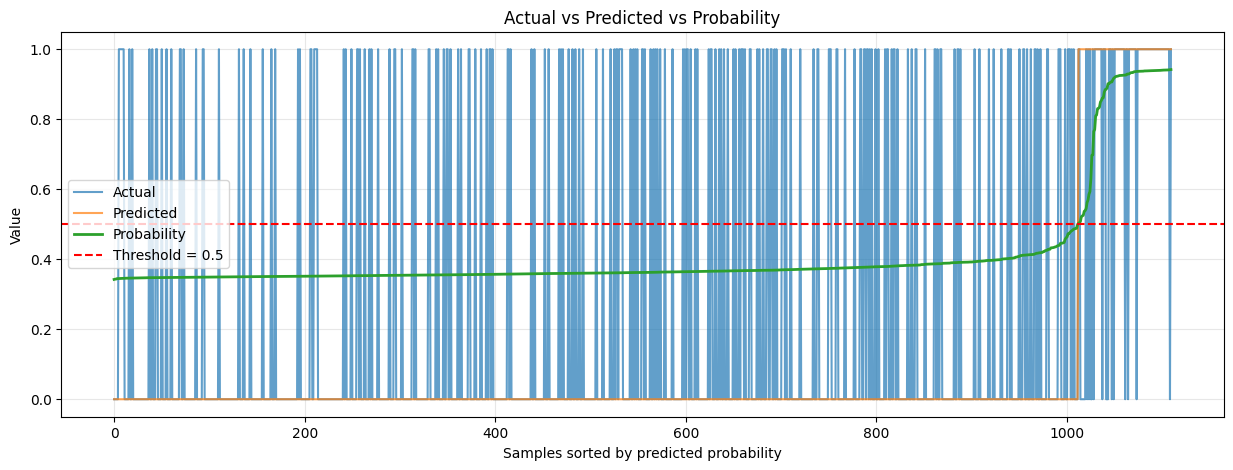

In [32]:
visu = visu.sort_values(by='y_prob').reset_index(drop=True)

# Plot
plt.figure(figsize=(15, 5))

plt.plot(visu['y_true'], label='Actual', alpha=0.7)
plt.plot(visu['y_pred'], label='Predicted', alpha=0.7)
plt.plot(visu['y_prob'], label='Probability', linewidth=2)

plt.axhline(0.5, color='red', linestyle='--', label='Threshold = 0.5')

plt.xlabel('Samples sorted by predicted probability')
plt.ylabel('Value')
plt.title('Actual vs Predicted vs Probability')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

35/35 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


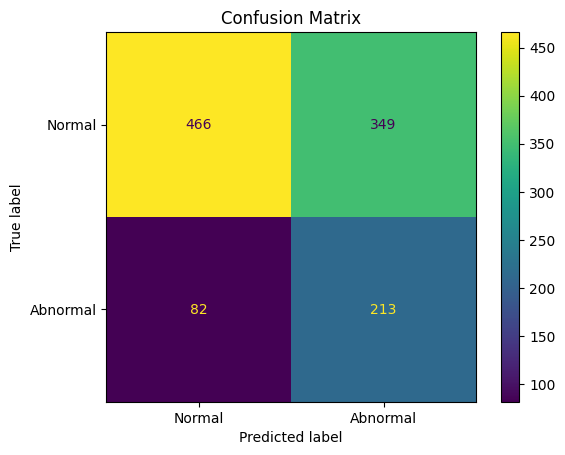

In [11]:
model_evaluate(rnn_model, X_test, y_test)